<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-070f-circuit-autoencoder.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 070f. A quantum circuit autoencoder

The quantum autoencoder compresses a family of quantum states into fewer qubits. Quantum information is also stored in circuits, for example in a set of circuits that load data into a register or in an imperfect device whose action we know only as a black box. The quantum circuit autoencoder (QCAE) of Ref. [1] compresses such a circuit. Two encoder circuits, $\hat U$ placed before and $\hat V$ placed after the unknown circuit, concentrate its whole action on a smaller number of qubits, and running the encoders backwards restores the original circuit.

A circuit is a map from input states to output states, and a map is harder to handle than a state. The Choi–Jamiołkowski isomorphism [2, 3] turns every circuit, and more generally every quantum channel, into a quantum state on twice as many qubits. The tools developed for states then carry over to circuits, so two circuits are compared by the fidelity of their Choi states, and the eigenvalues of this state decide how far the circuit can be compressed, in the same way as the eigenvalues of the average density matrix did for the quantum autoencoder of states.

| | The task of this notebook |
|---|---|
| **Input** | an unknown channel $\mathcal E$ on $N=3$ qubits, available as a black box that we can run on any input, including one half of entangled pairs. Here $\mathcal E$ applies one of $n_{\rm f}=6$ circuits chosen at random. |
| **Output** | encoder circuits $\hat U$, $\hat V$ and a compressed channel $\mathcal F$ on $N-k=1$ qubit, from which $\tilde{\mathcal E}=\hat V^\dagger\circ(\mathcal F\otimes{\rm id})\circ\hat U^\dagger$ rebuilds the channel |
| **Trained** | the angles of $\hat U(\boldsymbol\theta)$ and $\hat V(\boldsymbol\varphi)$, hardware-efficient circuits with 18 angles each |
| **Loss** | measured on the $k=2$ trash qubits only, one minus the mean probability that a trash qubit and its partner pass a test for a Bell pair |
| **Success** | the fidelity of the Choi states of $\tilde{\mathcal E}$ and $\mathcal E$ close to 1. It can never exceed a bound set by the spectrum of the Choi state of $\mathcal E$. |

Sections 2 to 6 build the Choi–Jamiołkowski isomorphism on one qubit and then on three qubits. Sections 7 to 10 define the circuit autoencoder, train it on a compressible channel and show a channel that cannot be compressed. All results are exact simulations of state vectors and density matrices, whereas on a device the loss would be estimated from measured bit strings. The whole notebook runs in well under a minute on a laptop CPU. Section 11 states the scope and limitations of the example, and Section 12 holds exercises for home.

## 1. Double-precision arithmetic

We work in double precision on the CPU. NumPy builds channels, Choi states and fidelities, JAX computes the gradients of the training loss, and Matplotlib draws the figures. Every random seed is fixed.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # small calculations, never the GPU
import json, time
from itertools import product
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
TOL = 1e-10
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
NAVY, BLUE, ORANGE, GRAY, GREEN = "#002B5C", "#3E8FD0", "#D35A05", "#5A6270", "#1B7F36"
plt.rcParams.update({"font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "legend.fontsize": 11.5, "figure.figsize": (4.8, 3.2), "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42})
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)
started = time.perf_counter()
RESULTS = {}
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Circuits and channels

A circuit made of gates acts on a pure state as a unitary matrix, $|\psi\rangle\mapsto\hat U|\psi\rangle$, and on a density matrix as $\hat\rho\mapsto\hat U\hat\rho\,\hat U^\dagger$. A noisy device, or a circuit chosen at random from a list, does more than a single unitary. Its general action is a **quantum channel** $\mathcal E$, a linear map of density matrices that can always be written in the Kraus form
$$\mathcal E(\hat\rho)=\sum_{a}\hat K_a\,\hat\rho\,\hat K_a^\dagger ,\qquad \sum_a\hat K_a^\dagger\hat K_a=\hat I . \tag{1}$$
The condition on the Kraus operators $\hat K_a$ keeps the trace equal to one, and the form of (1) keeps the output positive. A unitary circuit is the special case of a single Kraus operator $\hat K_1=\hat U$. A circuit $\hat U_j$ chosen with probability $p_j$ has the Kraus operators $\sqrt{p_j}\,\hat U_j$.

We use four channels on one qubit as running examples, from no change at all to complete loss of information.

* The **identity** ${\rm id}(\hat\rho)=\hat\rho$, a wire with nothing on it.
* The **Hadamard gate** $\hat\rho\mapsto\hat H\hat\rho\hat H$, a unitary channel.
* **Dephasing** $\hat\rho\mapsto(1-p)\hat\rho+p\hat Z\hat\rho\hat Z$, which applies $\hat Z$ with probability $p$. It keeps the populations of $|0\rangle$ and $|1\rangle$ and shrinks the off-diagonal elements by $1-2p$.
* **Complete depolarisation** $\hat\rho\mapsto\hat I/2$, which forgets the input. Its Kraus operators are $\hat I/2$, $\hat X/2$, $\hat Y/2$, $\hat Z/2$, since $\frac14(\hat\rho+\hat X\hat\rho\hat X+\hat Y\hat\rho\hat Y+\hat Z\hat\rho\hat Z)=\frac12\hat I\,{\rm Tr}\,\hat\rho$.

To compare or compress a channel we need its action on every input, because two channels can agree on a few inputs and differ on others. The Choi state of Section 3 collects this complete action in a single density matrix.

In [2]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]])
Z = np.diag([1.0 + 0j, -1.0])
H = (X + Z) / np.sqrt(2)
P_DEPH = 0.2

def apply_channel(kraus, rho):
    """Kraus form, equation (1)."""
    return sum(K @ rho @ K.conj().T for K in kraus)

CHANNELS_1Q = {
    "identity":     [I2],
    "Hadamard":     [H],
    "dephasing":    [np.sqrt(1 - P_DEPH) * I2, np.sqrt(P_DEPH) * Z],
    "depolarising": [I2 / 2, X / 2, Y / 2, Z / 2],
}
rng = np.random.default_rng(1)
def random_density_matrix(dim, r):
    A = r.normal(size=(dim, dim)) + 1j * r.normal(size=(dim, dim))
    rho = A @ A.conj().T
    return rho / np.trace(rho)

rho_test = random_density_matrix(2, rng)
for name, kraus in CHANNELS_1Q.items():
    assert np.allclose(sum(K.conj().T @ K for K in kraus), I2)              # trace preservation
    out = apply_channel(kraus, rho_test)
    assert abs(np.trace(out) - 1) < TOL and np.linalg.eigvalsh(out).min() > -TOL
assert np.allclose(apply_channel(CHANNELS_1Q["depolarising"], rho_test), I2 / 2)
off_in, off_out = rho_test[0, 1], apply_channel(CHANNELS_1Q["dephasing"], rho_test)[0, 1]
assert np.isclose(off_out, (1 - 2 * P_DEPH) * off_in)
print("all four channels are trace preserving and positive on a random input")
print(f"dephasing p = {P_DEPH}: off-diagonal element shrinks by {abs(off_out / off_in):.2f}")

all four channels are trace preserving and positive on a random input
dephasing p = 0.2: off-diagonal element shrinks by 0.60


## 3. The Choi–Jamiołkowski state

To capture the action on all inputs at once, we feed the channel one half of a maximally entangled state. For a register of dimension $D$ ($D=2$ for one qubit, $D=2^N$ for $N$ qubits) we take a second register of the same size, the **reference**, and prepare
$$|\Phi^+\rangle=\frac1{\sqrt D}\sum_{i=0}^{D-1}|i\rangle_S\otimes|i\rangle_R , \tag{2}$$
where $S$ labels the system, the register on which the channel acts, and $\{|i\rangle\}$ is the computational basis. For one qubit this is the Bell state $(|00\rangle+|11\rangle)/\sqrt2$. The channel acts on the system half while the reference is left untouched, and the resulting state of both registers is the **Choi state**
$$\hat J_{\mathcal E}=(\mathcal E\otimes{\rm id})\big(|\Phi^+\rangle\langle\Phi^+|\big)=\frac1D\sum_{i,j=0}^{D-1}\mathcal E\big(|i\rangle\langle j|\big)\otimes|i\rangle\langle j| . \tag{3}$$
The second form follows by inserting (2) and using the linearity of $\mathcal E$. It shows that $\hat J_{\mathcal E}$ lists the images of all matrix units $|i\rangle\langle j|$, and these images fix $\mathcal E$ on every input, since every $\hat\rho=\sum_{ij}\rho_{ij}|i\rangle\langle j|$ is a combination of them. The map $\mathcal E\mapsto\hat J_{\mathcal E}$ is the Choi–Jamiołkowski isomorphism [2, 3]. Because $\mathcal E$ maps density matrices to density matrices also when it acts on half of a larger system, $\hat J_{\mathcal E}$ is a density matrix of the $2N$ qubits, positive with unit trace. Tracing out the system gives ${\rm Tr}_S\,\hat J_{\mathcal E}=\hat I/D$, so the reference alone stays maximally mixed whatever the channel does.

The spectrum of $\hat J_{\mathcal E}$ follows from the Kraus form (1), in which each Kraus operator turns the entangled state into a vector $|K_a\rangle\!\rangle=(\hat K_a\otimes\hat I)|\Phi^+\rangle$, so
$$\hat J_{\mathcal E}=\sum_a|K_a\rangle\!\rangle\langle\!\langle K_a| . \tag{4}$$
The rank of $\hat J_{\mathcal E}$ is therefore the smallest number of Kraus operators needed for $\mathcal E$, called the **Kraus rank**. A unitary circuit has one Kraus operator and a pure Choi state of rank one. A channel that injects more randomness needs more Kraus operators and has a more mixed Choi state. We compute the Choi states of the four one-qubit channels.

In [3]:
def choi(kraus):
    """Choi state (3): system first, reference second, from the Kraus operators via (4)."""
    D = kraus[0].shape[0]
    phi = np.eye(D).reshape(-1) / np.sqrt(D)              # |Phi+>, amplitude of |i>_S|j>_R at index i*D + j
    vecs = [np.kron(K, np.eye(D)) @ phi for K in kraus]   # |K_a>>
    return sum(np.outer(v, v.conj()) for v in vecs)

def choi_from_matrix_units(kraus):
    """Second form of (3), as a check."""
    D = kraus[0].shape[0]
    J = np.zeros((D * D, D * D), dtype=complex)
    for i in range(D):
        for j in range(D):
            Eij = np.zeros((D, D)); Eij[i, j] = 1.0
            J += np.kron(apply_channel(kraus, Eij), Eij) / D
    return J

def partial_trace_system(J, D):
    return np.einsum("sasb->ab", J.reshape(D, D, D, D))

phi_bell = np.array([1, 0, 0, 1]) / np.sqrt(2)
CHOI_1Q, TABLE = {}, []
for name, kraus in CHANNELS_1Q.items():
    J = choi(kraus)
    assert np.allclose(J, choi_from_matrix_units(kraus))
    assert np.allclose(J, J.conj().T) and abs(np.trace(J) - 1) < TOL and np.linalg.eigvalsh(J).min() > -TOL
    assert np.allclose(partial_trace_system(J, 2), I2 / 2)            # reference stays maximally mixed
    lam = np.sort(np.linalg.eigvalsh(J))[::-1]
    lam = np.where(np.abs(lam) < 1e-12, 0.0, lam)
    rank = int(np.sum(lam > 1e-10))
    stacked = np.array([K.reshape(-1) for K in kraus])
    assert rank == np.linalg.matrix_rank(stacked)                      # Choi rank = Kraus rank
    CHOI_1Q[name] = J
    TABLE.append((name, np.round(lam.real, 3), rank, np.trace(J @ J).real))

assert np.allclose(CHOI_1Q["identity"], np.outer(phi_bell, phi_bell))  # the Bell state itself
assert np.allclose(CHOI_1Q["depolarising"], np.eye(4) / 4)             # maximally mixed
assert np.allclose(sorted(np.linalg.eigvalsh(CHOI_1Q["dephasing"])), [0, 0, P_DEPH, 1 - P_DEPH])
print(f"{'channel':>13s} | {'eigenvalues of J':>24s} | rank | purity Tr J^2")
for name, lam, rank, pur in TABLE:
    print(f"{name:>13s} | {str(lam):>24s} | {rank:4d} | {pur:.3f}")
RESULTS["choi_one_qubit"] = {name: {"eigenvalues": lam.tolist(), "rank": rank, "purity": pur} for name, lam, rank, pur in TABLE}

      channel |         eigenvalues of J | rank | purity Tr J^2
     identity |            [1. 0. 0. 0.] |    1 | 1.000
     Hadamard |            [1. 0. 0. 0.] |    1 | 1.000
    dephasing |        [0.8 0.2 0.  0. ] |    2 | 0.680
 depolarising |    [0.25 0.25 0.25 0.25] |    4 | 0.250


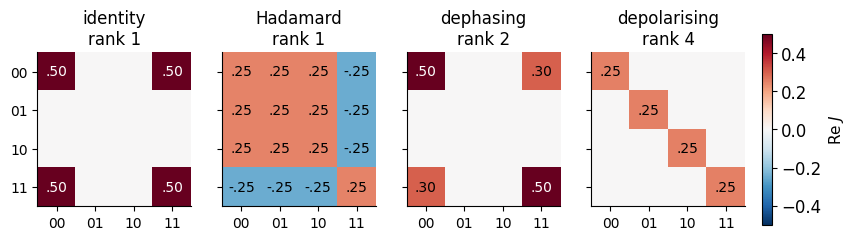

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(11.0, 3.1))
labels = ["00", "01", "10", "11"]
for ax, (name, lam, rank, pur) in zip(axes, TABLE):
    J = CHOI_1Q[name].real
    im = ax.imshow(J, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_xticklabels(labels, fontsize=10); ax.set_yticklabels(labels if ax is axes[0] else [], fontsize=10)
    ax.set_title(f"{name}\nrank {rank}", fontsize=12)
    for i in range(4):
        for j in range(4):
            if abs(J[i, j]) > 1e-12:
                ax.text(j, i, f"{J[i, j]:.2f}".replace("0.", "."), ha="center", va="center", fontsize=10,
                        color="white" if abs(J[i, j]) > 0.3 else "black")
cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02); cb.set_label(r"Re $J$", fontsize=11)
save(fig, "fig_lab070f_choi_onequbit"); plt.show()

Rows and columns are labelled by the system bit followed by the reference bit. The identity channel leaves the Bell state $(|00\rangle+|11\rangle)/\sqrt2$, whose density matrix has the four entries $1/2$ in the corners. The Hadamard gate gives another pure state, with entries of both signs, and it also has rank one. Dephasing keeps the diagonal and shrinks the corner coherences from $1/2$ to $(1-2p)/2=0.3$, so its Choi state mixes two pure states with weights $1-p$ and $p$, rank two. The completely depolarising channel produces $\hat I/4$, the maximally mixed state of two qubits, of rank four.

## 4. Reading the channel back from its Choi state

To find the output of the channel for an input $\hat\rho$ from its Choi state, we multiply the reference by the transpose $\hat\rho^{T}$ and trace out the reference,
$$\mathcal E(\hat\rho)=D\,{\rm Tr}_R\big[(\hat I\otimes\hat\rho^{T})\,\hat J_{\mathcal E}\big] . \tag{5}$$
The derivation uses the second form of (3). The reference factor of the term $(i,j)$ gives ${\rm Tr}\big[\hat\rho^{T}|i\rangle\langle j|\big]=\langle j|\hat\rho^{T}|i\rangle=\rho_{ij}$, so
$$D\,{\rm Tr}_R\big[(\hat I\otimes\hat\rho^{T})\hat J_{\mathcal E}\big]=\sum_{i,j}\rho_{ij}\,\mathcal E\big(|i\rangle\langle j|\big)=\mathcal E\Big(\sum_{i,j}\rho_{ij}|i\rangle\langle j|\Big)=\mathcal E(\hat\rho) .$$
The map from channels to Choi states can therefore be inverted, and no information about $\mathcal E$ is lost. We check (5) on random inputs for the four channels.

In [5]:
def channel_from_choi(J, rho):
    """Equation (5): D Tr_R[(I x rho^T) J]."""
    D = rho.shape[0]
    return D * np.einsum("ab,satb->st", rho, J.reshape(D, D, D, D))

worst = 0.0
for name, kraus in CHANNELS_1Q.items():
    for _ in range(5):
        rho = random_density_matrix(2, rng)
        worst = max(worst, np.abs(channel_from_choi(CHOI_1Q[name], rho) - apply_channel(kraus, rho)).max())
assert worst < 1e-12
print(f"largest deviation between (5) and the Kraus form over 20 random inputs: {worst:.1e}")

largest deviation between (5) and the Kraus form over 20 random inputs: 3.3e-16


## 5. Preparing the Choi state of a circuit

On a device the Choi state of an $N$-qubit circuit is prepared with $N$ Bell pairs. Qubit $q$ of the system is paired with qubit $q$ of the reference, each pair is put into $(|00\rangle+|11\rangle)/\sqrt2$ by a Hadamard gate and a controlled-NOT gate, and the circuit then acts on the system half (panel (a) of the sketch). The product of the $N$ pairs is the state (2) with $D=2^N$, because the sum over all bit strings $i$ of $|i\rangle_S|i\rangle_R$ factorises into one sum per qubit. Preparing $\hat J_{\mathcal E}$ thus needs $2N$ qubits, twice the size of the circuit. Panel (b) shows the register used later to train the autoencoder.

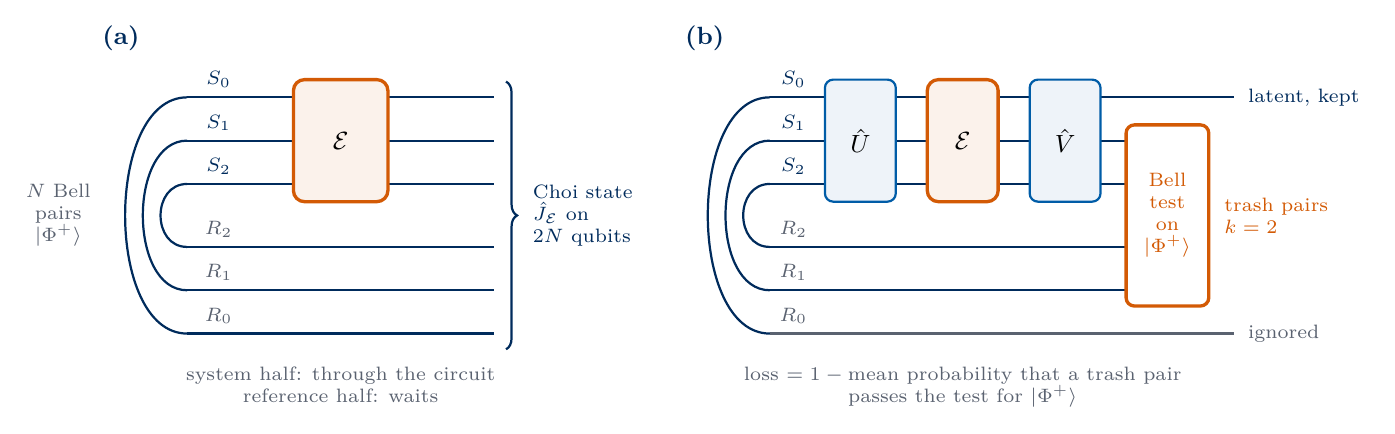

We check the factorisation for $N=3$ and the Choi state of a unitary circuit. For a unitary $\hat W$ the state $(\hat W\otimes\hat I)|\Phi^+\rangle$ has the amplitudes $W_{ij}/\sqrt D$, the matrix of the circuit read as a vector.

In [6]:
N = 3
D = 2 ** N
bell_pairs = np.kron(np.kron(phi_bell, phi_bell), phi_bell)          # qubit order S0 R0 S1 R1 S2 R2
reordered = bell_pairs.reshape([2] * 6).transpose(0, 2, 4, 1, 3, 5).reshape(-1)   # order S0 S1 S2 R0 R1 R2
assert np.allclose(reordered, np.eye(D).reshape(-1) / np.sqrt(D))    # N Bell pairs = |Phi+> of (2)

def random_unitary(dim, r):
    Q, R = np.linalg.qr(r.normal(size=(dim, dim)) + 1j * r.normal(size=(dim, dim)))
    return Q * (np.diag(R) / np.abs(np.diag(R)))

W_test = random_unitary(D, rng)
psi_choi = np.kron(W_test, np.eye(D)) @ reordered                    # one half of each pair through the circuit
assert np.allclose(psi_choi, W_test.reshape(-1) / np.sqrt(D))
J_W = np.outer(psi_choi, psi_choi.conj())
assert np.allclose(J_W, choi([W_test])) and abs(np.trace(J_W @ J_W) - 1) < TOL
print(f"N = {N}: three Bell pairs give |Phi+> on {2 * N} qubits; the Choi state of a random circuit is pure (rank 1)")

N = 3: three Bell pairs give |Phi+> on 6 qubits; the Choi state of a random circuit is pure (rank 1)


## 6. Comparing two circuits by their Choi states

Two channels are compared through their Choi states with the fidelity of density matrices,
$$F(\hat\rho,\hat\sigma)=\Big({\rm Tr}\sqrt{\sqrt{\hat\rho}\,\hat\sigma\sqrt{\hat\rho}}\Big)^2 , \tag{6}$$
which reduces to $\langle\psi|\hat\sigma|\psi\rangle$ when $\hat\rho=|\psi\rangle\langle\psi|$ is pure, the fidelity used for the quantum autoencoder of states. The **Choi fidelity** $F(\hat J_{\mathcal E_1},\hat J_{\mathcal E_2})$ equals one only for identical channels. For two unitary circuits both Choi states are pure and $F=|{\rm Tr}(\hat W_1^\dagger\hat W_2)|^2/D^2$. For the identity and the dephasing channel it is $\langle\Phi^+|\hat J_{\rm deph}|\Phi^+\rangle=1-p$.

The Choi fidelity describes the channel on average over inputs, since for a channel $\mathcal E$ compared with a unitary $\hat W$ the fidelity $\langle\psi|\hat W^\dagger\mathcal E(|\psi\rangle\langle\psi|)\hat W|\psi\rangle$ averaged over all pure inputs equals $(DF+1)/(D+1)$ with $F$ the Choi fidelity [4, 5]. A Choi fidelity close to one therefore guarantees a good output on average, while a single input can still have a lower fidelity. For one qubit the average over all pure states equals the average over the six eigenstates of $\hat X$, $\hat Y$, $\hat Z$, because the quantity averaged is quadratic in $|\psi\rangle\langle\psi|$, and we use this to check the formula for dephasing.

In [7]:
def psd_sqrt(A):
    w, v = np.linalg.eigh(A)
    return (v * np.sqrt(np.clip(w, 0, None))) @ v.conj().T

def fidelity(A, B):
    """Equation (6), computed as the squared sum of singular values of sqrt(A) sqrt(B)."""
    return float(np.sum(np.linalg.svd(psd_sqrt(A) @ psd_sqrt(B), compute_uv=False)) ** 2)

W2 = random_unitary(D, rng)
assert abs(fidelity(choi([W_test]), choi([W2])) - abs(np.trace(W_test.conj().T @ W2)) ** 2 / D ** 2) < 1e-10
F_id_deph = fidelity(CHOI_1Q["identity"], CHOI_1Q["dephasing"])
assert abs(F_id_deph - (1 - P_DEPH)) < 1e-10

six_states = [np.array(v, dtype=complex) / np.linalg.norm(v) for v in
              ([1, 0], [0, 1], [1, 1], [1, -1], [1, 1j], [1, -1j])]
F_avg = np.mean([np.real(s.conj() @ apply_channel(CHANNELS_1Q["dephasing"], np.outer(s, s.conj())) @ s) for s in six_states])
assert abs(F_avg - (2 * F_id_deph + 1) / 3) < 1e-12
print(f"Choi fidelity identity vs dephasing (p = {P_DEPH}): {F_id_deph:.3f} = 1 - p")
print(f"average output fidelity over inputs: {F_avg:.4f} = (2F + 1)/3; worst input (|+>): {1 - P_DEPH:.3f}")
RESULTS["choi_fidelity_identity_dephasing"] = F_id_deph

Choi fidelity identity vs dephasing (p = 0.2): 0.800 = 1 - p
average output fidelity over inputs: 0.8667 = (2F + 1)/3; worst input (|+>): 0.800


## 7. The quantum circuit autoencoder

We now compress a channel $\mathcal E$ on $N$ qubits into $N-k$ qubits. As for states, the last $k$ qubits are called trash qubits and the first $N-k$ latent qubits. Ref. [1] writes $n$ for our $N$ and $m$ for our $N-k$. The compression uses two encoders, a unitary $\hat U$ applied before $\mathcal E$ and a unitary $\hat V$ applied after it, so the **encoded channel** is $\Lambda=\hat V\circ\mathcal E\circ\hat U$, where $\circ$ means "then" read from right to left. The **compressed channel** $\mathcal F$ on the latent qubits keeps the part of $\Lambda$ that acts on them. It feeds the trash qubits with the maximally mixed state and discards them afterwards,
$$\mathcal F(\hat\sigma)={\rm Tr}_{\rm trash}\Big[\Lambda\big(\hat\sigma\otimes\hat I/2^k\big)\Big] . \tag{7}$$
In terms of Choi states, $\hat J_{\mathcal F}$ is $\hat J_\Lambda$ with the trash qubits and their reference partners traced out. To run the circuit again we decode by placing $\mathcal F$ next to an untouched trash register and undoing the encoders,
$$\tilde{\mathcal E}=\hat V^\dagger\circ(\mathcal F\otimes{\rm id}_{\rm trash})\circ\hat U^\dagger . \tag{8}$$
The reconstruction is **lossless**, $\tilde{\mathcal E}=\mathcal E$, exactly when $\Lambda=\mathcal F\otimes{\rm id}_{\rm trash}$, so that after the encoders the circuit acts only on the latent qubits and passes the trash qubits through unchanged (Proposition 1 of Ref. [1]). Then $\tilde{\mathcal E}=\hat V^\dagger\circ\Lambda\circ\hat U^\dagger=\mathcal E$.

The encoders act on the two halves of the Choi state separately. Since $(\hat U\otimes\hat I)|\Phi^+\rangle=(\hat I\otimes\hat U^{T})|\Phi^+\rangle$,
$$\hat J_{\hat V\circ\mathcal E\circ\hat U}=(\hat V\otimes\hat U^{T})\,\hat J_{\mathcal E}\,(\hat V\otimes\hat U^{T})^\dagger , \tag{9}$$
so $\hat V$ rotates the output half and $\hat U^T$ the input half. Equation (9) is a unitary change of basis, so the encoders leave the eigenvalues of the Choi state unchanged.

A single unitary circuit $\hat W$ is trivial to compress, because the choice $\hat U=\hat I$, $\hat V=\hat W^\dagger$ gives $\Lambda={\rm id}$, which is of the lossless form with $\mathcal F={\rm id}$, and (8) returns $\hat W$. The information then sits in the encoders, as a single state could always be compressed by its own preparation circuit. The task becomes meaningful for a family of circuits $\hat W_1,\dots,\hat W_{n_{\rm f}}$ that must share one pair of encoders. We describe the family by the channel that applies one of them at random,
$$\mathcal E(\hat\rho)=\frac1{n_{\rm f}}\sum_{j=1}^{n_{\rm f}}\hat W_j\hat\rho\,\hat W_j^\dagger , \tag{10}$$
whose Choi state is the average of the pure Choi states of the members, the analogue of the average density matrix of a family of states.

By (9), the decoded Choi state $\hat J_{\tilde{\mathcal E}}$ is a unitary rotation of $\hat J_{\mathcal F}\otimes|\Phi^+\rangle\langle\Phi^+|_{\rm trash}$. The latent Choi state $\hat J_{\mathcal F}$ lives on $2(N-k)$ qubits and has rank at most $d^2$ with $d=2^{N-k}$, and the trash factor is pure, so $\hat J_{\tilde{\mathcal E}}$ has rank at most $d^2$. The fidelity of a state $\hat\rho$ with any state of rank $r$ is at most the sum of the $r$ largest eigenvalues of $\hat\rho$, which gives Proposition 3 of Ref. [1],
$$F\big(\hat J_{\mathcal E},\hat J_{\tilde{\mathcal E}}\big)\le\sum_{i=1}^{d^2}\lambda_i , \tag{11}$$
with $\lambda_1\ge\lambda_2\ge\dots$ the eigenvalues of $\hat J_{\mathcal E}$. A channel can be compressed well into $N-k$ qubits only if its Choi state carries almost all its weight on $d^2=4^{N-k}$ eigenvectors. The bound depends on $\mathcal E$ alone, since by (9) no choice of encoders changes the spectrum.

We implement (7) to (9) and check them, including the trivial compression of a single circuit.

In [8]:
K_TRASH = 2
DL, DC = 2 ** (N - K_TRASH), 2 ** K_TRASH            # latent and trash dimensions, D = DL * DC, d = DL

def choi_mixture(Ws):
    """Choi state of the random choice (10) among the unitaries Ws, via (4)."""
    vecs = np.asarray(Ws).reshape(len(Ws), -1) / np.sqrt(D)
    return np.einsum("ja,jb->ab", vecs, vecs.conj()) / len(Ws)

def compressed_choi(U, V, Ws):
    """Choi state of F, equation (7): trace the trash output and its reference partner out of J_Lambda."""
    G = np.einsum("ab,jbc,cd->jad", V, np.asarray(Ws), U)                  # members of Lambda = V o E o U
    JL = choi_mixture(G).reshape(DL, DC, DL, DC, DL, DC, DL, DC)            # (a, c, a~, c~ ; a', c', a~', c~')
    return np.einsum("acbdecfd->abef", JL).reshape(DL * DL, DL * DL)

def reconstructed_choi(U, V, Ws):
    """Choi state of E~, equation (8), using (9) with V^dagger on the output and (U^dagger)^T on the input half."""
    JF = compressed_choi(U, V, Ws).reshape(DL, DL, DL, DL)
    phi_trash = np.einsum("cd,gh->cdgh", np.eye(DC), np.eye(DC)) / DC       # |Phi+><Phi+| of the trash pairs
    JP = np.einsum("abef,cdgh->acbdegfh", JF, phi_trash).reshape(D * D, D * D)
    M = np.kron(V.conj().T, U.conj())
    return M @ JP @ M.conj().T

# checks: (9), (7) against a direct calculation, and the trivial compression of one circuit
Ws_test = [random_unitary(D, rng) for _ in range(3)]
U_r, V_r = random_unitary(D, rng), random_unitary(D, rng)
M9 = np.kron(V_r, U_r.T)
assert np.allclose(choi_mixture([V_r @ W @ U_r for W in Ws_test]), M9 @ choi_mixture(Ws_test) @ M9.conj().T)
sigma = random_density_matrix(DL, rng)
F_direct = sum(np.einsum("acbc->ab", (V_r @ W @ U_r @ np.kron(sigma, np.eye(DC) / DC) @ (V_r @ W @ U_r).conj().T)
                         .reshape(DL, DC, DL, DC)) for W in Ws_test) / 3
assert np.allclose(channel_from_choi(compressed_choi(U_r, V_r, Ws_test), sigma), F_direct)
J_rec = reconstructed_choi(U_r, V_r, Ws_test)
assert abs(np.trace(J_rec) - 1) < TOL and np.linalg.eigvalsh(J_rec).min() > -TOL
assert np.linalg.matrix_rank(J_rec, tol=1e-10) <= DL ** 2
F_single = fidelity(choi([W_test]), reconstructed_choi(np.eye(D), W_test.conj().T, [W_test]))
assert abs(F_single - 1) < 1e-10
print(f"N = {N}, k = {K_TRASH}: latent dimension d = {DL}, at most d^2 = {DL ** 2} eigenvalues survive")
print(f"one random circuit, U = I, V = W^dagger: Choi fidelity {F_single:.10f}")

N = 3, k = 2: latent dimension d = 2, at most d^2 = 4 eigenvalues survive
one random circuit, U = I, V = W^dagger: Choi fidelity 1.0000000000


## 8. A compressible family of circuits

We build a family whose members do something nontrivial to only one qubit, hidden by a fixed scrambling circuit,
$$\hat W_j=\hat S\,\big(\hat R_j\otimes\hat I\otimes\hat I\big)\,\hat S^\dagger ,\qquad j=1,\dots,6 . \tag{12}$$
Each $\hat R_j$ is a random single-qubit unitary and $\hat S$ is a fixed three-qubit circuit with random angles, a hardware-efficient circuit of two layers defined in the next cell. Every $\hat W_j$ looks like a generic entangling three-qubit unitary, whereas in the basis rotated by $\hat S$ all six act on the first qubit only and leave the other two unchanged. The encoders $\hat U=\hat S$ and $\hat V=\hat S^\dagger$ undo the scrambling and give $\Lambda=(\text{random choice of }\hat R_j)\otimes{\rm id}$, which is of the lossless form with one latent qubit.

The Choi state of the channel (10) then has rank at most four, the Choi rank of a channel on one qubit, so the bound (11) with $d^2=4$ equals one. We compute the spectrum and check that the encoders built from $\hat S$ reconstruct the channel exactly. This analytic reference construction uses our knowledge of $\hat S$, which the training in Section 9 does not have.

The hardware-efficient circuit consists of $L$ layers, each a rotation $\hat R_z(\theta)\hat R_y(\theta')$ on every qubit followed by a chain of controlled-$Z$ gates, and a final rotation block, $2N(L+1)=18$ angles for $N=3$ and $L=2$.

In [9]:
L = 2
N_F = 6

def ry(t):
    c, s = jnp.cos(t / 2), jnp.sin(t / 2)
    return jnp.array([[c, -s], [s, c]], dtype=complex)

def rz(t):
    return jnp.array([[jnp.exp(-0.5j * t), 0], [0, jnp.exp(0.5j * t)]])

def bits(i):
    return [(i >> (N - 1 - q)) & 1 for q in range(N)]
CZ_CHAIN = np.diag([(-1.0) ** sum(bits(i)[q] * bits(i)[q + 1] for q in range(N - 1)) for i in range(D)]).astype(complex)

def hea(theta):
    """Hardware-efficient circuit, theta of shape (L+1, N, 2): Ry then Rz on each qubit, CZ chain between blocks."""
    U = jnp.eye(D, dtype=complex)
    for l in range(L + 1):
        layer = rz(theta[l, 0, 1]) @ ry(theta[l, 0, 0])
        for q in range(1, N):
            layer = jnp.kron(layer, rz(theta[l, q, 1]) @ ry(theta[l, q, 0]))
        U = layer @ U
        if l < L:
            U = CZ_CHAIN @ U
    return U

rng_family = np.random.default_rng(7)
theta_S = rng_family.uniform(0, 2 * np.pi, (L + 1, N, 2))
S = np.array(hea(theta_S))                                            # the hidden scrambler

def random_qubit_unitary(r):
    a, b, c = r.uniform(0, 2 * np.pi, 3)
    return np.array(rz(a) @ ry(b) @ rz(c))

R_list = [random_qubit_unitary(rng_family) for _ in range(N_F)]
W_family = np.array([S @ np.kron(R, np.eye(DC)) @ S.conj().T for R in R_list])   # equation (12)
J_comp = choi_mixture(W_family)
lam_comp = np.sort(np.linalg.eigvalsh(J_comp))[::-1]
rank_comp = int(np.sum(lam_comp > 1e-10))
bound_comp = lam_comp[:DL ** 2].sum()
assert rank_comp <= DL ** 2 and abs(bound_comp - 1) < 1e-10
F_hand = fidelity(J_comp, reconstructed_choi(S, S.conj().T, W_family))
assert abs(F_hand - 1) < 1e-8
print("largest eigenvalues of J_E:", np.round(lam_comp[:6], 4))
print(f"Choi rank = {rank_comp}, bound (11) = sum of the {DL ** 2} largest = {bound_comp:.6f}")
print(f"encoders built from the known scrambler, U = S, V = S^dagger: Choi fidelity = {F_hand:.10f}")
RESULTS.update(lam_comp=lam_comp[:8].tolist(), rank_comp=rank_comp, bound_comp=bound_comp, F_hand=F_hand)

largest eigenvalues of J_E: [0.4609 0.3234 0.1751 0.0406 0.     0.    ]
Choi rank = 4, bound (11) = sum of the 4 largest = 1.000000
encoders built from the known scrambler, U = S, V = S^dagger: Choi fidelity = 1.0000000000


## 9. Training the encoders on the trash qubits

Without knowledge of $\hat S$ we train hardware-efficient encoders $\hat U(\boldsymbol\theta)={\rm HEA}(\boldsymbol\theta)$ and $\hat V(\boldsymbol\varphi)={\rm HEA}(\boldsymbol\varphi)^\dagger$, with 18 angles each. Computing the Choi fidelity (6) during training would require the full $2N$-qubit Choi states of both channels side by side. The variational algorithm of Ref. [1], called varQCAE, avoids this and measures only the trash qubits, in the register of panel (b) of the sketch.

1. Prepare $N$ Bell pairs and apply $\hat U$, the black box $\mathcal E$ and $\hat V$ to the system half. The register is then in the Choi state $\hat J_\Lambda$ of the encoded channel.
2. Ignore the latent qubit and its reference partner. The latent input then looks maximally mixed, which is the input of (7).
3. For every trash qubit $c$ test whether it still forms the Bell pair $|\Phi^+\rangle$ with its reference partner $\tilde c$. On a device the test is a controlled-NOT from $c$ to $\tilde c$, a Hadamard gate on $c$ and a measurement of both qubits, and the outcome $00$ means that the pair passed.

The loss is one minus the pass probability averaged over the $k$ trash pairs,
$$\mathcal L(\boldsymbol\theta,\boldsymbol\varphi)=1-\frac1k\sum_{c\in{\rm trash}}\langle\Phi^+|\hat\rho_{c\tilde c}|\Phi^+\rangle , \tag{13}$$
where $\hat\rho_{c\tilde c}$ is the reduced state of the pair in $\hat J_\Lambda$. Like the trash Hamming distance of the state autoencoder, it is a sum of terms that each involve two qubits, a local cost. For the random choice (10) the reduced state is the average over the members, so (13) is the average of the member losses.

The loss vanishes if and only if the encoded channel is lossless. If every trash pair leaves as a perfect Bell pair, $\Lambda$ has passed each trash qubit through unchanged. A qubit in a pure maximally entangled state with its partner has no correlations with any third system, so nothing from the latent qubit has entered the trash qubits and nothing has left them. Hence $\Lambda=\mathcal F\otimes{\rm id}_{\rm trash}$, and by Section 7 the reconstruction is exact (Proposition 1 of Ref. [1]). Training the trash pairs alone therefore trains the whole autoencoder. We implement (13) and check that it vanishes for the encoders built from $\hat S$.

In [10]:
PHI2 = jnp.array([1.0, 0.0, 0.0, 1.0]) / np.sqrt(2)

def trash_loss(params, Ws):
    """Equation (13) for the random choice among the unitaries Ws, N = 3 and trash qubits 1, 2."""
    th, ph = params
    U, V = hea(th), hea(ph).conj().T
    psi = jnp.einsum("ab,jbc,cd->jad", V, Ws, U) / np.sqrt(D)             # Choi vectors of the members of Lambda
    psi = psi.reshape(-1, DL, DC, DL, DC)                                  # (a, c, a~, c~): system then reference
    rho = jnp.einsum("jacbd,jaebf->jcdef", psi, psi.conj())                # trash qubits and their partners
    rho = rho.reshape(-1, 2, 2, 2, 2, 2, 2, 2, 2)                          # (c1, c2, c~1, c~2 ; primed)
    pair1 = jnp.einsum("jxuyvzuwv->jxyzw", rho).reshape(-1, 4, 4)          # (c1, c~1)
    pair2 = jnp.einsum("juxvyuzvw->jxyzw", rho).reshape(-1, 4, 4)          # (c2, c~2)
    p1 = jnp.einsum("a,jab,b->j", PHI2, pair1, PHI2).real
    p2 = jnp.einsum("a,jab,b->j", PHI2, pair2, PHI2).real
    return 1.0 - jnp.mean((p1 + p2) / 2)

W_family_j = jnp.asarray(W_family)
loss_hand = float(trash_loss((jnp.asarray(theta_S), jnp.asarray(theta_S)), W_family_j))
assert abs(loss_hand) < 1e-12
print(f"loss (13) for U = S, V = S^dagger: {loss_hand:.1e}")

loss (13) for U = S, V = S^dagger: 4.4e-16


We train 16 starts with random angles in parallel, each for 400 steps of the Adam optimiser [6] with step size 0.05, and gradients from automatic differentiation. We use several starts because the loss of the encoders has local minima. After training we evaluate the Choi fidelity of the reconstruction, which the training never saw.

In [11]:
STARTS, STEPS, LR = 16, 400, 0.05
value_and_grad = jax.jit(jax.vmap(jax.value_and_grad(trash_loss), in_axes=(0, None)))
k1, k2 = jax.random.split(jax.random.PRNGKey(0))
shape = (STARTS, L + 1, N, 2)
params0 = (2 * np.pi * jax.random.uniform(k1, shape), 2 * np.pi * jax.random.uniform(k2, shape))

def train(Ws):
    """Adam on all starts at once. Returns the loss history, snapshots of the angles and the first gradient size."""
    Ws = jnp.asarray(Ws)
    params = params0
    m = jax.tree_util.tree_map(jnp.zeros_like, params)
    v = jax.tree_util.tree_map(jnp.zeros_like, params)
    losses, snaps, g0 = [], {}, None
    for t in range(1, STEPS + 1):
        if t == 1 or t % 10 == 0:
            snaps[t - 1] = jax.tree_util.tree_map(np.array, params)
        loss, g = value_and_grad(params, Ws)
        if g0 is None:
            g0 = float(max(jnp.abs(g[0]).max(), jnp.abs(g[1]).max()))
        losses.append(np.array(loss))
        m = jax.tree_util.tree_map(lambda m, g: 0.9 * m + 0.1 * g, m, g)
        v = jax.tree_util.tree_map(lambda v, g: 0.999 * v + 0.001 * g * g, v, g)
        params = jax.tree_util.tree_map(
            lambda p, m, v: p - LR * (m / (1 - 0.9 ** t)) / (jnp.sqrt(v / (1 - 0.999 ** t)) + 1e-8), params, m, v)
    snaps[STEPS] = jax.tree_util.tree_map(np.array, params)
    losses.append(np.array(value_and_grad(params, Ws)[0]))
    return np.array(losses), snaps, g0

def choi_fidelity_of(snap, s, Ws, J):
    U = np.array(hea(snap[0][s])); V = np.array(hea(snap[1][s])).conj().T
    return fidelity(J, reconstructed_choi(U, V, Ws))

t0 = time.perf_counter()
loss_comp, snaps_comp, _ = train(W_family)
best = int(np.argmin(loss_comp[-1]))
steps_ck = np.array(sorted(snaps_comp))
F_curve = np.array([choi_fidelity_of(snaps_comp[t], best, W_family, J_comp) for t in steps_ck])
F_final = np.array([choi_fidelity_of(snaps_comp[STEPS], s, W_family, J_comp) for s in range(STARTS)])
assert np.all(F_final <= bound_comp + 1e-8)                               # bound (11) for every start
n_success = int(np.sum(loss_comp[-1] < 1e-3))
print(f"training time: {time.perf_counter() - t0:.1f} s")
print(f"starts with final loss below 1e-3: {n_success} of {STARTS}")
print("final losses (sorted):", np.round(np.sort(loss_comp[-1]), 4))
print("Choi fidelities after training (sorted):", np.round(np.sort(F_final), 4))
print(f"best start: loss {loss_comp[-1, best]:.1e}, Choi fidelity {F_curve[-1]:.6f}, bound {bound_comp:.6f}")
RESULTS.update(n_success=n_success, starts=STARTS, steps=STEPS, best_loss=float(loss_comp[-1, best]),
               best_choi_fidelity=float(F_curve[-1]), final_losses=np.sort(loss_comp[-1]).tolist(),
               final_choi_fidelities=np.sort(F_final).tolist())

training time: 3.2 s
starts with final loss below 1e-3: 7 of 16
final losses (sorted): [0.000e+00 0.000e+00 1.000e-04 2.000e-04 2.000e-04 2.000e-04 3.000e-04
 1.933e-01 1.934e-01 1.934e-01 1.940e-01 1.940e-01 1.940e-01 2.105e-01
 2.105e-01 2.105e-01]
Choi fidelities after training (sorted): [0.3377 0.3377 0.3377 0.4585 0.4585 0.4585 0.4588 0.4589 0.4589 0.9997
 0.9997 0.9998 0.9998 0.9999 1.     1.    ]
best start: loss 1.5e-05, Choi fidelity 0.999982, bound 1.000000


## 10. A channel that cannot be compressed

The completely depolarising channel on three qubits, $\mathcal E(\hat\rho)=\hat I/8$, forgets its input. It is the random choice (10) among all 64 products of Pauli matrices $\hat I,\hat X,\hat Y,\hat Z$ on the three qubits, so its Choi state follows from the same code. By (3) it equals $\hat I/64$, all 64 eigenvalues are equal, and the bound (11) is $4/64=1/16$. No pair of encoders can exceed this bound. The loss (13) does not depend on the angles at all, because the output is maximally mixed and uncorrelated with the reference. Every trash pair is then in the state $\hat I/4$ and passes the Bell test with probability $1/4$ whatever the encoders are, so the loss is $3/4$ and its gradient vanishes. We train with the same starts and compare the spectra.

depolarising: bound = 0.0625, loss = 0.7500 at every step, largest gradient component 6.9e-17, Choi fidelity = 0.0625


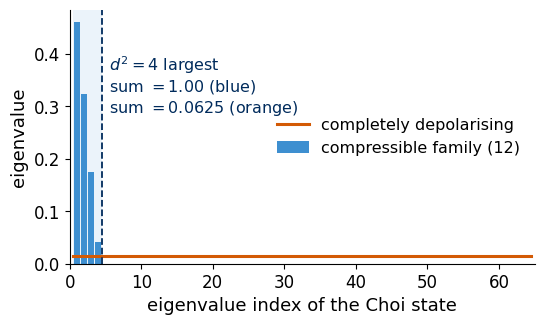

In [12]:
PAULI = [I2, X, Y, Z]
W_dep = np.array([np.kron(np.kron(PAULI[a], PAULI[b]), PAULI[c]) for a, b, c in product(range(4), repeat=3)])
J_dep = choi_mixture(W_dep)
assert np.allclose(J_dep, np.eye(D * D) / D ** 2)
lam_dep = np.sort(np.linalg.eigvalsh(J_dep))[::-1]
bound_dep = lam_dep[:DL ** 2].sum()

loss_dep, snaps_dep, g0_dep = train(W_dep)
F_dep_curve = np.array([choi_fidelity_of(snaps_dep[t], 0, W_dep, J_dep) for t in steps_ck])
assert np.allclose(loss_dep, 0.75, atol=1e-12) and g0_dep < 1e-12
assert np.allclose(F_dep_curve, 1 / 16, atol=1e-10) and abs(bound_dep - 1 / 16) < 1e-12
print(f"depolarising: bound = {bound_dep:.4f}, loss = {loss_dep[0, 0]:.4f} at every step, "
      f"largest gradient component {g0_dep:.1e}, Choi fidelity = {F_dep_curve[-1]:.4f}")
RESULTS.update(bound_dep=bound_dep, loss_dep=float(loss_dep[0, 0]), F_dep=float(F_dep_curve[-1]))

fig, ax = plt.subplots(figsize=(6.0, 3.3))
idx = np.arange(1, D * D + 1)
ax.axvspan(0.5, DL ** 2 + 0.5, color=BLUE, alpha=0.10, lw=0)
ax.bar(idx, np.clip(lam_comp, 0, None), width=0.8, color=BLUE, label="compressible family (12)")
ax.step(np.r_[0.5, idx + 0.5], np.r_[lam_dep[0], lam_dep], where="pre", color=ORANGE, lw=2.2, label="completely depolarising")
ax.axvline(DL ** 2 + 0.5, color=NAVY, ls="--", lw=1.3)
ax.text(DL ** 2 + 1.5, 0.40, rf"$d^2={DL ** 2}$ largest" "\n" rf"sum $={bound_comp:.2f}$ (blue)" "\n" rf"sum $={bound_dep:.4f}$ (orange)",
        fontsize=11.5, color=NAVY, va="top")
ax.set_xlim(0, D * D + 1)
ax.set_xlabel("eigenvalue index of the Choi state")
ax.set_ylabel("eigenvalue")
ax.legend(loc="center right", frameon=False)
save(fig, "fig_lab070f_spectrum"); plt.show()

The compressible family has four nonzero eigenvalues, all inside the shaded window of the $d^2=4$ largest, so the bound (11) allows a perfect reconstruction with one latent qubit. The depolarising channel spreads its weight evenly over all 64 eigenvalues, and only $1/16$ of it fits into the window.

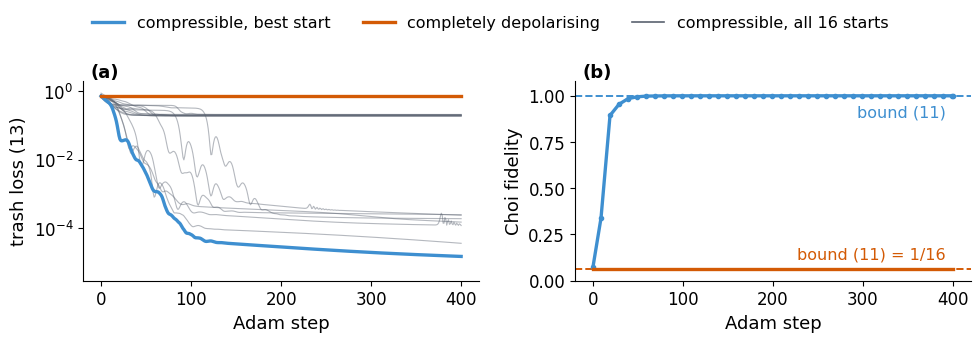

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.0, 3.5))
x = np.arange(STEPS + 1)
for s in range(STARTS):
    a1.semilogy(x, np.maximum(loss_comp[:, s], 1e-12), color=GRAY, lw=0.8, alpha=0.45)
a1.semilogy(x, np.maximum(loss_comp[:, best], 1e-12), color=BLUE, lw=2.4, label="compressible, best start")
a1.semilogy(x, loss_dep[:, 0], color=ORANGE, lw=2.4, label="completely depolarising")
a1.plot([], [], color=GRAY, lw=1.2, label=f"compressible, all {STARTS} starts")
a1.set_xlabel("Adam step"); a1.set_ylabel("trash loss (13)"); a1.set_ylim(3e-6, 2)
a1.text(0.02, 1.0, "(a)", transform=a1.transAxes, fontsize=13, fontweight="bold", va="bottom")
a2.axhline(bound_comp, color=BLUE, ls="--", lw=1.4); a2.axhline(bound_dep, color=ORANGE, ls="--", lw=1.4)
a2.plot(steps_ck, F_curve, color=BLUE, lw=2.4, marker="o", ms=3)
a2.plot(steps_ck, F_dep_curve, color=ORANGE, lw=2.4)
a2.text(STEPS * 0.98, bound_comp - 0.05, "bound (11)", color=BLUE, ha="right", va="top", fontsize=11.5)
a2.text(STEPS * 0.98, bound_dep + 0.04, "bound (11) = 1/16", color=ORANGE, ha="right", va="bottom", fontsize=11.5)
a2.set_xlabel("Adam step"); a2.set_ylabel("Choi fidelity"); a2.set_ylim(0, 1.08)
a2.text(0.02, 1.0, "(b)", transform=a2.transAxes, fontsize=13, fontweight="bold", va="bottom")
fig.tight_layout(w_pad=2.0, rect=(0, 0, 1, 0.88))
fig.legend(*a1.get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False, fontsize=11.5, bbox_to_anchor=(0.5, 1.0))
save(fig, "fig_lab070f_training"); plt.show()

Panel (a) shows the trash loss (13) of all 16 starts in grey. Seven starts fall below $10^{-3}$ and approach the lossless encoders, while the other nine stop on plateaus near $0.19$ and $0.21$, local minima of the loss. The best start (blue) reaches a loss of about $10^{-5}$. Panel (b) shows the Choi fidelity of the reconstruction for this start, computed from the full Choi states, which the training never used. It rises to the bound (11) together with the fall of the trash loss, as Proposition 1 predicts. The depolarising channel (orange) has a constant loss of $3/4$ and a Choi fidelity fixed at its bound $1/16$, and no training can change either. The listed final values show that the starts stuck on plateaus also reconstruct poorly, with Choi fidelities between about $0.34$ and $0.46$, so a low trash loss identifies the starts to keep.

## 11. Scope and limitations of the example

* The Choi fidelity measures the reconstruction averaged over inputs, as Section 6 showed. A reconstruction with Choi fidelity close to one can still fail on a few inputs.
* Preparing a Choi state and running the Bell tests requires $2N$ qubits and $N$ Bell pairs, twice the size of the circuit being compressed.
* The family (12) was built from the same hardware-efficient circuit as the encoders, so we knew that lossless encoders exist inside the ansatz. For an unknown black box the right depth of the encoders and the existence of such encoders are unknown in advance, and the bound (11) is only an upper limit.
* Nine of the 16 starts end in local minima. The trash loss identifies them without access to the full Choi states.
* All numbers come from an exact simulation of three qubits. On a device each pass probability in (13) would be estimated from a finite number of Bell-test shots, and its gradient from the parameter-shift rule.
* Ref. [1] also uses the trained autoencoder to flag anomalous circuits through their reconstruction fidelity and to reduce depolarising noise. We did not reproduce these applications here.

## 12. Exercises

1. Compute the Choi state of the amplitude-damping channel with Kraus operators $\hat K_0=|0\rangle\langle0|+\sqrt{1-\gamma}\,|1\rangle\langle1|$ and $\hat K_1=\sqrt\gamma\,|0\rangle\langle1|$. Find its rank and check equation (5) on a random input.
2. Replace the family (12) by six independent random three-qubit unitaries. Compute the spectrum of the Choi state and the bound (11) for one latent qubit, train the encoders, and compare the best Choi fidelity with the bound.
3. Add dephasing with probability $p$ on qubit 0 after every member of (12). Predict the eigenvalues of the Choi state and the bound, then train and check.
4. Estimate the loss (13) of the best start from $M=1000$ simulated Bell-test shots per trash pair and compare the shot noise with the trained value.
5. Increase the number of starts to 64 and record which fraction reaches a loss below $10^{-3}$.

## 13. Summary

The Choi–Jamiołkowski isomorphism turns a channel on $N$ qubits into a density matrix on $2N$ qubits, prepared by sending one half of $N$ Bell pairs through the channel. The map can be inverted by equation (5), so the Choi state contains the whole channel. Its rank is the Kraus rank, one for a unitary circuit and $4^N$ for complete depolarisation, and the fidelity of two Choi states compares two channels averaged over inputs. The quantum circuit autoencoder wraps an unknown channel in encoders $\hat U$ and $\hat V$ and keeps the part that acts on $N-k$ latent qubits. The reconstruction is lossless exactly when the encoded channel passes the trash qubits through unchanged, so a loss measured on the trash pairs alone trains the whole autoencoder. Its Choi fidelity cannot exceed the sum of the $4^{N-k}$ largest eigenvalues of the Choi state. A family of six three-qubit circuits that hide a one-qubit action reaches this bound after training, while the completely depolarising channel stays at $1/16$ with a loss that no choice of encoders changes.

## References

1. J. Wu, H. Fu, M. Zhu, H. Zhang, W. Xie and X.-Y. Li, Quantum circuit autoencoder, Phys. Rev. A **109**, 032623 (2024), [doi:10.1103/PhysRevA.109.032623](https://doi.org/10.1103/PhysRevA.109.032623).
2. M.-D. Choi, Completely positive linear maps on complex matrices, Linear Algebra Appl. **10**, 285 (1975), [doi:10.1016/0024-3795(75)90075-0](https://doi.org/10.1016/0024-3795(75)90075-0).
3. A. Jamiołkowski, Linear transformations which preserve trace and positive semidefiniteness of operators, Rep. Math. Phys. **3**, 275 (1972), [doi:10.1016/0034-4877(72)90011-0](https://doi.org/10.1016/0034-4877(72)90011-0).
4. M. Horodecki, P. Horodecki and R. Horodecki, General teleportation channel, singlet fraction, and quasidistillation, Phys. Rev. A **60**, 1888 (1999), [doi:10.1103/PhysRevA.60.1888](https://doi.org/10.1103/PhysRevA.60.1888).
5. M. A. Nielsen, A simple formula for the average gate fidelity of a quantum dynamical operation, Phys. Lett. A **303**, 249 (2002), [doi:10.1016/S0375-9601(02)01272-0](https://doi.org/10.1016/S0375-9601(02)01272-0).
6. D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).